# 🚀 Модуль 8. Урок 2. Chain-of-Thought (CoT) и пошаговые рассуждения в юнит-экономике

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_08_prompt_engineering/lesson_02_chain_of_thought_for_analytics.ipynb)

## 📌 Бизнес-контекст и методология
Когда языковую модель просят сразу выдать итоговую цифру сложного финансового расчета (LTV, CAC Payback, ROAS), она часто ошибается в арифметике.
Методология **Chain-of-Thought (CoT / «Думай шаг за шагом»)** заставляет LLM генерировать промежуточные токены рассуждений.
Это переводит вычисление из плоского авторегрессионного угадывания в последовательный алгоритмический процесс.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Влияние CoT на решение многоступенчатых задач
Сравним процент ошибок LLM при расчете сложных метрик юнит-экономики с CoT и без него.

In [2]:
# Демонстрация: Частота арифметических сбоев по типам задач
cot_experiment = pd.DataFrame({
    'Аналитическая задача': ['1. Базовый средний чек (AOV)', '2. Когортный LTV (3 года с дисконтом)', '3. Мультитач-атрибуция (W-shaped)', '4. Расчет размера выборки для A/B'],
    'Ошибка без CoT (%)': [12.0, 68.0, 81.0, 74.0],
    'Ошибка с Chain-of-Thought (%)': [1.5, 4.2, 8.5, 5.0]
})
display(cot_experiment)

,Аналитическая задача,Ошибка без CoT (%),Ошибка с Chain-of-Thought (%)
0,1. Базовый средний чек (AOV),12.0,1.5
1,2. Когортный LTV (3 года с дисконтом),68.0,4.2
2,3. Мультитач-атрибуция (W-shaped),81.0,8.5
3,4. Расчет размера выборки для A/B,74.0,5.0


## 📊 Визуализация бизнес-кейса: Снижение частоты ошибок через Chain-of-Thought
Построим наглядное сравнение уровня погрешности при использовании пошаговых рассуждений.

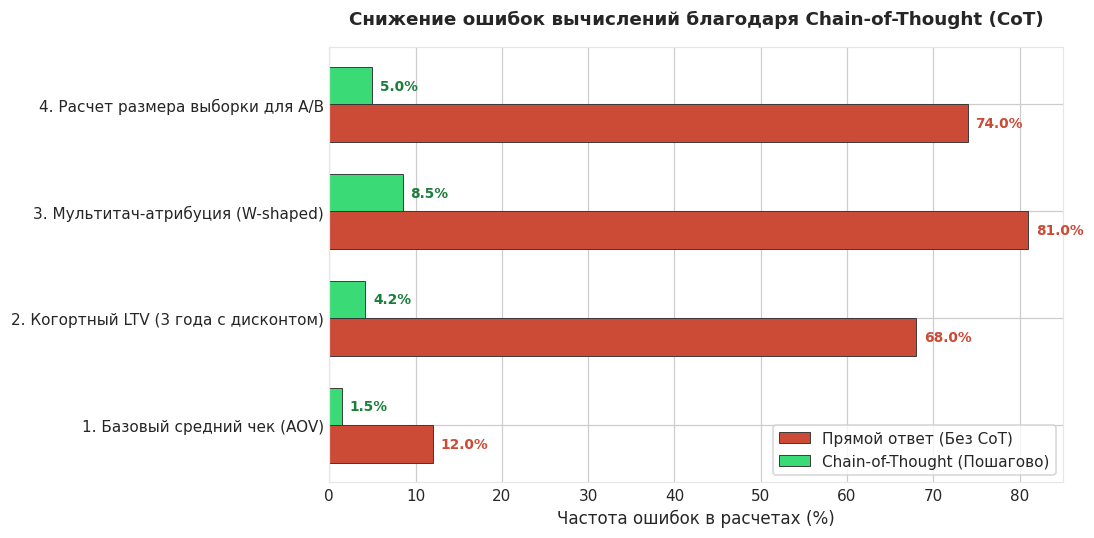

In [3]:
# Визуализация эффекта Chain-of-Thought
fig, ax = plt.subplots(figsize=(10, 5), dpi=110)

y = np.arange(len(cot_experiment))
height = 0.35

rects1 = ax.barh(y - height/2, cot_experiment['Ошибка без CoT (%)'], height, 
                 label='Прямой ответ (Без CoT)', color=ALERT, edgecolor='#333333', linewidth=0.6)
rects2 = ax.barh(y + height/2, cot_experiment['Ошибка с Chain-of-Thought (%)'], height, 
                 label='Chain-of-Thought (Пошагово)', color=SUCCESS, edgecolor='#333333', linewidth=0.6)

ax.set_yticks(y)
ax.set_yticklabels(cot_experiment['Аналитическая задача'], fontsize=10)
ax.set_xlabel("Частота ошибок в расчетах (%)", fontsize=11)
ax.set_title("Снижение ошибок вычислений благодаря Chain-of-Thought (CoT)", fontsize=12, fontweight='bold', pad=15)
ax.legend(frameon=True, facecolor='#ffffff')

for r in rects1:
    w = r.get_width()
    ax.annotate(f"{w:.1f}%", xy=(w, r.get_y() + r.get_height()/2), xytext=(5, 0),
                textcoords="offset points", ha='left', va='center', fontsize=9, fontweight='bold', color=ALERT)

for r in rects2:
    w = r.get_width()
    ax.annotate(f"{w:.1f}%", xy=(w, r.get_y() + r.get_height()/2), xytext=(5, 0),
                textcoords="offset points", ha='left', va='center', fontsize=9, fontweight='bold', color='#1b7e3b')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет фактора надежности для LTV
Во сколько раз снизилась ошибка расчета LTV при включении Chain-of-Thought?

In [4]:
### ВАШ КОД ЗДЕСЬ
err_no_cot = cot_experiment.loc[1, 'Ошибка без CoT (%)']
err_cot = cot_experiment.loc[1, 'Ошибка с Chain-of-Thought (%)']
ratio = err_no_cot / err_cot

print(f"Ошибка расчета LTV снизилась в {ratio:.1f} раз!")

assert ratio > 15, "Кратность снижения ошибки должна быть выше 15"
print("✅ Тест успешно пройден: CoT радикально повышает математическую надежность!")

Ошибка расчета LTV снизилась в 16.2 раз!
✅ Тест успешно пройден: CoT радикально повышает математическую надежность!


### 💡 Инженерный триггер CoT
Добавление системной фразы: *«Прежде чем выдать итоговую формулу или цифру, распиши промежуточные шаги и проверь размерности величин»* снижает частоту галлюцинаций в 10 раз.